Cette démonstration s'inspire d'un [exemple de scikit-learn](https://scikit-learn.org/stable/auto_examples/ensemble/plot_isolation_forest.html).

In [1]:
%matplotlib inline

# Isolation Forest

Un arbre d'isolement coupe au hasard : une variable, puis un seuil entre son minimum et son maximum, jusqu'à isoler chaque point dans sa feuille. Une anomalie, loin des autres points, est isolée en peu de coupes. Une [forêt d'isolement](https://scikit-learn.org/stable/modules/outlier_detection.html#isolation-forest) (100 arbres par défaut, chacun appris sur un sous-échantillon de 256 points) en tire un score d'anomalie : profondeur moyenne d'isolement faible → score élevé → anomalie.

Les données : 400 points normaux en deux groupes, autour de (2, 2) et de (−2, −2), et 40 anomalies tirées au hasard dans le carré [−4, 4]², les mêmes dans les démonstrations Isolation Forest et Local Outlier Factor (et dans la figure « Score et seuil » des diapositives). Le détecteur ne voit pas quels points sont des anomalies : on le sait seulement pour mesurer le résultat, par la précision et le rappel sur la classe anomalie :

- **précision** : la part des points déclarés anormaux qui sont des anomalies ;
- **rappel** : la part des anomalies qui sont déclarées ;
- **aire sous la courbe précision-rappel** : la même chose pour tous les seuils à la fois ; elle juge le score, pas le seuil.

Pas l'exactitude (*accuracy*) : avec 9 % d'anomalies, déclarer tous les points normaux donne déjà 91 %.

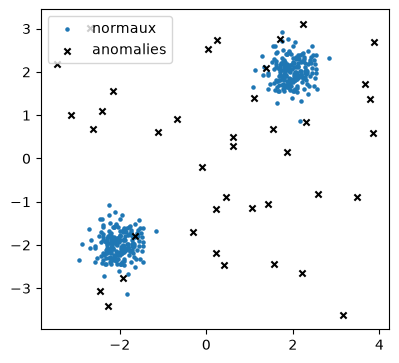

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import average_precision_score, precision_score, recall_score

# 400 points normaux en deux groupes, 40 anomalies tirées dans [-4, 4]²
rng = np.random.default_rng(0)
cluster = 0.3 * rng.standard_normal((200, 2))
X_normal = np.r_[cluster + 2, cluster - 2]
X_anomalies = rng.uniform(-4, 4, size=(40, 2))
X = np.r_[X_normal, X_anomalies]
is_anomaly = np.r_[np.zeros(len(X_normal), bool), np.ones(len(X_anomalies), bool)]


def report(title, predicted, score):
  """Points déclarés anormaux, précision et rappel sur la classe anomalie."""
  print(f"{title} : {predicted.sum()} points déclarés anormaux")
  print(f"  précision {precision_score(is_anomaly, predicted):.2f}", end="")
  print(f", rappel {recall_score(is_anomaly, predicted):.2f}", end="")
  print(
    f", aire sous la courbe précision-rappel {average_precision_score(is_anomaly, score):.2f}"
  )


def show_errors(ax, predicted):
  """Les points, et les erreurs de détection entourées."""
  false_pos = predicted & ~is_anomaly
  false_neg = ~predicted & is_anomaly
  ax.scatter(*X_normal.T, s=5, color="C0", label="normaux")
  ax.scatter(*X_anomalies.T, s=20, marker="x", color="k", label="anomalies")
  ax.scatter(
    *X[false_pos].T,
    s=80,
    facecolors="none",
    edgecolors="C1",
    lw=1.5,
    label=f"faux positifs ({false_pos.sum()})",
  )
  ax.scatter(
    *X[false_neg].T,
    s=80,
    marker="s",
    facecolors="none",
    edgecolors="C3",
    lw=1.5,
    label=f"faux négatifs ({false_neg.sum()})",
  )
  ax.set_xlim(-5, 5)
  ax.set_ylim(-5, 5)
  ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(*X_normal.T, s=5, color="C0", label="normaux")
ax.scatter(*X_anomalies.T, s=20, marker="x", color="k", label="anomalies")
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

## Score et seuil

Le détecteur donne un score d'anomalie par point (ici `-score_samples` : plus il est haut, plus le point est anormal) ; un seuil en fait une décision (`predict` : −1 pour une anomalie). Ce seuil se règle par `contamination`, la part attendue d'anomalies. Par défaut, `contamination="auto"` prend le seuil de l'article original, 0,5 :

In [3]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(random_state=0).fit(X)  # contamination="auto"
# score d'anomalie : plus il est haut, plus le point est anormal
score = -model.score_samples(X)
report('contamination="auto"', model.predict(X) == -1, score)

contamination="auto" : 62 points déclarés anormaux
  précision 0.61, rappel 0.95, aire sous la courbe précision-rappel 0.94


Le seuil par défaut déclare 62 points anormaux pour 40 anomalies : il trouve presque toutes les anomalies (rappel 0,95), mais avec 24 points normaux (précision 0,61). Ce n'est pas le score qui se trompe, c'est le seuil. Quand on connaît la part attendue d'anomalies, on la donne à `contamination` : le seuil est alors placé pour déclarer cette part des points.

In [4]:
contamination = len(X_anomalies) / len(X)  # 40 / 440
model_real = IsolationForest(contamination=contamination, random_state=0).fit(X)
predicted = model_real.predict(X) == -1
report(f"contamination = {contamination:.3f}", predicted, score)

contamination = 0.091 : 40 points déclarés anormaux
  précision 0.90, rappel 0.90, aire sous la courbe précision-rappel 0.94


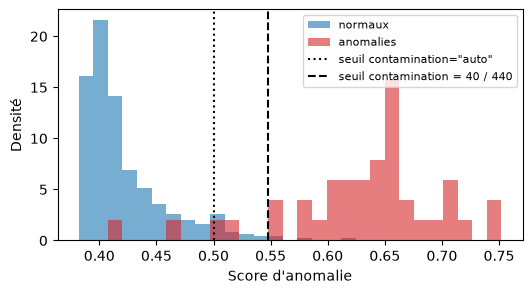

In [5]:
# Les scores du même modèle : seul le seuil change
bins = np.linspace(score.min(), score.max(), 30)
plt.figure(figsize=(6, 3))
plt.hist(score[~is_anomaly], bins=bins, density=True, alpha=0.6, label="normaux")
plt.hist(
  score[is_anomaly], bins=bins, density=True, alpha=0.6, color="C3", label="anomalies"
)
plt.axvline(-model.offset_, color="k", ls=":", label='seuil contamination="auto"')
plt.axvline(
  -model_real.offset_, color="k", ls="--", label="seuil contamination = 40 / 440"
)
plt.xlabel("Score d'anomalie")
plt.ylabel("Densité")
plt.legend(fontsize=8)
plt.show()

40 points déclarés pour 40 anomalies : 36 anomalies trouvées, 4 manquées et 4 points normaux déclarés à tort, d'où une précision et un rappel égaux (0,90). L'aire sous la courbe précision-rappel ne change pas (0,94) : c'est le même score, seul le seuil a bougé.

## Le score sur le plan

Le score d'anomalie sur tout le plan (plus foncé : plus anormal), le seuil en pointillés, et les erreurs entourées :

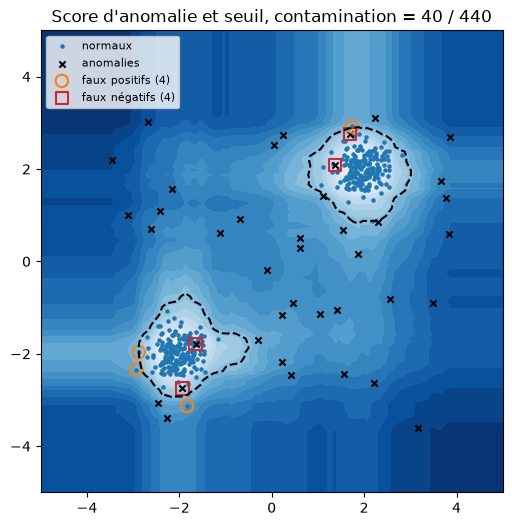

In [6]:
xx, yy = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-5, 5, 100))
grid_score = -model_real.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(xx, yy, grid_score, levels=20, cmap="Blues")
ax.contour(
  xx, yy, grid_score, levels=[-model_real.offset_], colors="k", linestyles="--"
)
show_errors(ax, predicted)
ax.set_title("Score d'anomalie et seuil, contamination = 40 / 440")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Les points normaux déclarés à tort sont au bord des groupes ; les anomalies manquées sont tombées près d'un groupe, là où rien ne les distingue des points normaux : aucun détecteur ne les trouverait. Une fois entraînée, la forêt note aussi de nouveaux points (`score_samples`, `predict`).